# Waste Collection Vehicles, Nonthaburi Province

**Data:** `data/raw/car.csv` — number of waste collection vehicles per local government per year (Buddhist Era 2563–2567 = 2020–2024) in 6 types: open side-tipper, rear-loading compactor, container truck, tipper truck, pickup, other

**Steps:** load → fill gaps with 0 and convert to integers → save `clean_car.csv` → charts: vehicles per year, share by vehicle type, by district, local governments with the most vehicles, and **waste load per vehicle**

# พาหนะที่ใช้ในการขนส่งขยะมูลฝอย จังหวัดนนทบุรี

**ข้อมูล:** `data/raw/car.csv` — จำนวนรถเก็บขนขยะราย อปท. รายปี (พ.ศ. 2563–2567) แยก 6 ประเภท: รถเปิดข้างเทท้าย, รถแบบอัดท้าย, รถคอนเทนเนอร์, รถบรรทุกเทท้าย, รถปิคอัพ, รถชนิดอื่นๆ

**ขั้นตอน:** โหลด → เติมค่าว่างเป็น 0 และแปลงเป็นจำนวนเต็ม → บันทึก `clean_car.csv` → กราฟ: จำนวนรถรายปี, สัดส่วนประเภทรถ, รายอำเภอ, อปท. ที่มีรถมาก และ **ภาระขยะต่อรถ 1 คัน**

**Import libraries** — `pandas` handles tabular data (DataFrame) and `numpy` handles numbers/missing values (`np.nan`)

**นำเข้าไลบรารี** — `pandas` ใช้จัดการข้อมูลแบบตาราง (DataFrame) และ `numpy` ใช้คำนวณตัวเลข/จัดการค่าว่าง (`np.nan`)

In [1]:
import pandas as pd
import numpy as np

**Load the raw data** from `../data/raw/car.csv`

**โหลดข้อมูลดิบ** จาก `../data/raw/car.csv`

In [2]:
df = pd.read_csv('../data/raw/car.csv')
df

,ปี,จังหวัด,อำเภอ,อปท,รถเปิดข้างเทท้าย/คัน,รถแบบอัดท้าย (คัน),รถคอนเทนเนอร์ (คัน),รถบรรทุกเทท้าย (คัน),รถปิคอัพ (คัน),รถชนิดอื่นๆ (คัน)
0,2563,นนทบุรี,ปากเกร็ด,เทศบาลนครปากเกร็ด,3.0,72.0,2.0,10.0,0.0,3.0
1,2563,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองไทรม้า,0.0,7.0,0.0,0.0,0.0,0.0
2,2563,นนทบุรี,บางกรวย,เทศบาลเมืองบางกรวย,0.0,16.0,2.0,0.0,0.0,0.0
3,2563,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางกร่าง,0.0,7.0,0.0,0.0,0.0,0.0
4,2563,นนทบุรี,บางบัวทอง,เทศบาลเมืองบางคูรัด,0.0,8.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
174,2567,นนทบุรี,ไทรน้อย,อบต.ราษฎร์นิยม,0.0,3.0,0.0,0.0,0.0,0.0
175,2567,นนทบุรี,บางบัวทอง,อบต.ละหาร,NaN,NaN,NaN,NaN,NaN,NaN
176,2567,นนทบุรี,บางบัวทอง,อบต.ลำโพ,0.0,5.0,0.0,0.0,1.0,0.0
177,2567,นนทบุรี,ไทรน้อย,อบต.หนองเพรางาย,NaN,NaN,NaN,NaN,NaN,NaN


**Check the data structure** with `df.info()` — number of rows, data types (dtype) and number of non-empty values in each column

Common issue: numeric columns with comma separators (e.g. `"1,234"`) are read as `object` (text) and must be converted to numbers before calculating

Some vehicle-count rows are empty (NaN), so these columns are read as `float`

**ตรวจสอบโครงสร้างข้อมูล** ด้วย `df.info()` — ดูจำนวนแถว ชนิดข้อมูล (dtype) และจำนวนค่าที่ไม่ว่างของแต่ละคอลัมน์

สิ่งที่มักพบ: คอลัมน์ตัวเลขที่มีเครื่องหมายจุลภาค (เช่น `"1,234"`) จะถูกอ่านเป็น `object` (ข้อความ) ต้องแปลงเป็นตัวเลขก่อนนำไปคำนวณ

คอลัมน์จำนวนรถบางแถวว่าง (NaN) ทำให้ถูกอ่านเป็น `float`

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 179 entries, 0 to 178
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ปี                    179 non-null    int64  
 1   จังหวัด               179 non-null    object 
 2   อำเภอ                 179 non-null    object 
 3   อปท                   179 non-null    object 
 4   รถเปิดข้างเทท้าย/คัน  134 non-null    float64
 5   รถแบบอัดท้าย (คัน)    142 non-null    float64
 6   รถคอนเทนเนอร์ (คัน)   135 non-null    float64
 7   รถบรรทุกเทท้าย (คัน)  136 non-null    float64
 8   รถปิคอัพ (คัน)        135 non-null    float64
 9   รถชนิดอื่นๆ (คัน)     136 non-null    float64
dtypes: float64(6), int64(1), object(3)
memory usage: 14.1+ KB


**Convert data types and fill gaps**
- `จังหวัด / อำเภอ / อปท` (province / district / local government) → `category`
- 6 vehicle-count columns: **fill gaps with 0** (interpreted as no vehicles of that type), then convert to `int` because vehicle counts must be whole numbers

**แปลงชนิดข้อมูลและเติมค่าว่าง**
- `จังหวัด / อำเภอ / อปท` → `category`
- 6 คอลัมน์จำนวนรถ: **เติมค่าว่างด้วย 0** (ตีความว่าไม่มีรถประเภทนั้น) แล้วแปลงเป็น `int` เพราะจำนวนรถต้องเป็นจำนวนเต็ม

In [4]:
for col in df.columns[1:4]:
    df[col] = df[col].astype('category')
# List of columns to fill
# รายชื่อคอลัมน์ที่ต้องการเติมค่า
cols_to_fill = [
    'รถเปิดข้างเทท้าย/คัน', 
    'รถแบบอัดท้าย (คัน)', 
    'รถคอนเทนเนอร์ (คัน)', 
    'รถบรรทุกเทท้าย (คัน)', 
    'รถปิคอัพ (คัน)', 
    'รถชนิดอื่นๆ (คัน)'
]

# Fill empty values with 0
# เติมค่าว่างด้วย 0
df[cols_to_fill] = df[cols_to_fill].fillna(0)

# Convert the data type from float to int (whole numbers)
# แปลงชนิดข้อมูลจาก float ให้เป็น int (จำนวนเต็ม)
df[cols_to_fill] = df[cols_to_fill].astype(int)

# Check the data again
# ตรวจสอบข้อมูลอีกครั้ง
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 179 entries, 0 to 178
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   ปี                    179 non-null    int64   
 1   จังหวัด               179 non-null    category
 2   อำเภอ                 179 non-null    category
 3   อปท                   179 non-null    category
 4   รถเปิดข้างเทท้าย/คัน  179 non-null    int64   
 5   รถแบบอัดท้าย (คัน)    179 non-null    int64   
 6   รถคอนเทนเนอร์ (คัน)   179 non-null    int64   
 7   รถบรรทุกเทท้าย (คัน)  179 non-null    int64   
 8   รถปิคอัพ (คัน)        179 non-null    int64   
 9   รถชนิดอื่นๆ (คัน)     179 non-null    int64   
dtypes: category(3), int64(7)
memory usage: 12.2 KB


**Check for duplicate rows** with `duplicated().sum()` — 0 means no rows are identical in every column, so nothing needs to be removed

**ตรวจแถวซ้ำ** ด้วย `duplicated().sum()` — ถ้าได้ 0 แปลว่าไม่มีแถวที่ข้อมูลเหมือนกันทุกคอลัมน์ ไม่ต้องลบอะไร

In [5]:
df.duplicated().sum()

np.int64(0)

**Save the cleaned data** to the `data/clean/` folder so other notebooks and the web app can use it

> Note: without `index=False` the CSV file gets a row-index column (it shows up as `Unnamed: 0` when read back)

**บันทึกข้อมูลที่ทำความสะอาดแล้ว** ลงโฟลเดอร์ `data/clean/` เพื่อให้ notebook อื่นและเว็บแอปนำไปใช้ต่อ

> หมายเหตุ: ถ้าไม่ใส่ `index=False` ไฟล์ CSV จะมีคอลัมน์ลำดับแถว (เปิดอ่านแล้วจะเห็นเป็น `Unnamed: 0`)

In [6]:
df.to_csv('../data/clean/clean_car.csv')

---
# Part 2: Data Visualization

This part turns the cleaned data into several kinds of charts to answer **"what is happening in this data"** across time (yearly/monthly), area (district/local government) and proportions

**The next cell sets up shared chart settings used by every chart:**
- Picks a **Thai font** available on the machine (Tahoma / Thonburi / Leelawadee UI, etc.) so Thai text does not turn into boxes
- Defines a **color palette (PALETTE)** tested for color-vision deficiency, and a fixed **color per district (DIST_COLOR)** — the same district has the same color in every chart and every notebook
- Creates **helper functions** `bar_labels` (numbers on bars), `stacked_bar` (stacked bar chart), `pie_chart` (pie chart)
- Creates a `viz` table, a copy of the data with category columns converted back to text so `groupby` is simple and produces no empty groups

# ส่วนที่ 2: การแสดงผลข้อมูล (Data Visualization)

ส่วนนี้นำข้อมูลที่ทำความสะอาดแล้วมาสร้างกราฟหลายรูปแบบ เพื่อตอบคำถามว่า **"เกิดอะไรขึ้นกับข้อมูลนี้"** ทั้งในมิติ เวลา (รายปี/รายเดือน) พื้นที่ (รายอำเภอ/อปท.) และสัดส่วน

**เซลล์ถัดไปเป็นการตั้งค่ากราฟที่ใช้ร่วมกันทุกกราฟ:**
- เลือก **ฟอนต์ภาษาไทย** ที่มีในเครื่อง (Tahoma / Thonburi / Leelawadee UI ฯลฯ) เพื่อไม่ให้ตัวอักษรไทยกลายเป็นสี่เหลี่ยม
- กำหนด **ชุดสี (PALETTE)** ที่ผ่านการทดสอบสำหรับผู้มีภาวะตาบอดสี และกำหนด **สีประจำอำเภอ (DIST_COLOR)** ให้คงที่ — อำเภอเดียวกันจะเป็นสีเดียวกันในทุกกราฟและทุก notebook
- สร้าง **ฟังก์ชันช่วย** `bar_labels` (ใส่ตัวเลขบนแท่ง), `stacked_bar` (กราฟแท่งซ้อน), `pie_chart` (แผนภูมิวงกลม)
- สร้างตาราง `viz` ซึ่งเป็นสำเนาของข้อมูลที่แปลงคอลัมน์ category กลับเป็นข้อความ เพื่อให้ `groupby` ทำงานง่ายและไม่เกิดกลุ่มว่าง

In [7]:
# ── Chart setup (shared by every chart in this section) ─────────────────
# ── ตั้งค่ากราฟ (ใช้ร่วมกันทุกกราฟในส่วนนี้) ─────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, to_rgb
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1) Thai font: pick the first one available on this machine
# 1) ฟอนต์ภาษาไทย: เลือกตัวแรกที่มีในเครื่อง
thai_fonts = ['Tahoma', 'Thonburi', 'Leelawadee UI', 'TH Sarabun New', 'Noto Sans Thai']
available = {f.name for f in fm.fontManager.ttflist}
thai_font = next((f for f in thai_fonts if f in available), 'DejaVu Sans')
plt.rcParams.update({
    'font.family': thai_font, 'axes.unicode_minus': False,
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#bdbcb6', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e8e7e2', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlepad': 12,
    'legend.frameon': False,
})
print(f'ใช้ฟอนต์: {thai_font}')

# 2) Color palette (fixed order — checked for color-vision-deficiency separation)
# 2) ชุดสี (เรียงลำดับคงที่ — ผ่านการตรวจความแตกต่างสำหรับผู้มีภาวะตาบอดสี)
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
GRAY = '#9a9992'
TEXT = '#52514e'
DIST_ORDER = ['เมืองนนทบุรี', 'บางกรวย', 'บางใหญ่', 'บางบัวทอง', 'ไทรน้อย', 'ปากเกร็ด']
DIST_COLOR = dict(zip(DIST_ORDER, PALETTE))           # color per district (fixed across all charts) — สีประจำอำเภอ (คงที่ทุกกราฟ)
MONTHS = ['มกราคม', 'กุมภาพันธ์', 'มีนาคม', 'เมษายน', 'พฤษภาคม', 'มิถุนายน',
          'กรกฎาคม', 'สิงหาคม', 'กันยายน', 'ตุลาคม', 'พฤศจิกายน', 'ธันวาคม']
MONTHS_SHORT = ['ม.ค.', 'ก.พ.', 'มี.ค.', 'เม.ย.', 'พ.ค.', 'มิ.ย.',
                'ก.ค.', 'ส.ค.', 'ก.ย.', 'ต.ค.', 'พ.ย.', 'ธ.ค.']
SEQ_CMAP = LinearSegmentedColormap.from_list('seq_blue', ['#eef4fc', '#86b6ef', '#2a78d6', '#104281'])
DIV_CMAP = LinearSegmentedColormap.from_list('div_blue_orange', ['#2a78d6', '#f0efec', '#eb6834'])
fmt_k = mtick.FuncFormatter(lambda x, _: f'{x:,.0f}')


def bar_labels(ax, bars, fmt='{:,.0f}', horizontal=False, fontsize=9):
    """Write the value at the end of each bar — เขียนตัวเลขกำกับที่ปลายแท่ง"""
    for b in bars:
        v = b.get_width() if horizontal else b.get_height()
        if horizontal:
            ax.text(v, b.get_y() + b.get_height() / 2, '  ' + fmt.format(v),
                    va='center', ha='left', fontsize=fontsize, color=TEXT)
        else:
            ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v),
                    ha='center', va='bottom', fontsize=fontsize, color=TEXT)


def stacked_bar(ax, table, colors=None, horizontal=False):
    """Stacked bar chart: table index = main axis, columns = stacked groups; returns each bar's total — กราฟแท่งซ้อน: index ของ table = แกนหลัก, columns = กลุ่มที่ซ้อนกัน; คืนค่ายอดรวมของแต่ละแท่ง"""
    if colors is None:
        colors = [DIST_COLOR.get(c, PALETTE[i % len(PALETTE)]) for i, c in enumerate(table.columns)]
    pos = np.arange(len(table))
    base = np.zeros(len(table))
    for c, color in zip(table.columns, colors):
        vals = table[c].fillna(0).to_numpy(dtype=float)
        if horizontal:
            ax.barh(pos, vals, left=base, color=color, edgecolor='white', linewidth=1, height=0.65, label=str(c))
        else:
            ax.bar(pos, vals, bottom=base, color=color, edgecolor='white', linewidth=1, width=0.65, label=str(c))
        base += vals
    if horizontal:
        ax.set_yticks(pos, [str(i) for i in table.index]); ax.grid(axis='y', visible=False)
    else:
        ax.set_xticks(pos, [str(i) for i in table.index]); ax.grid(axis='x', visible=False)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    return base


def end_labels(ax, x, items, min_gap_frac=0.045):
    """Labels at the end of lines (items = [(name, y value)]) — spaced apart automatically so they do not overlap — ชื่อกำกับที่ปลายเส้น (items = [(ชื่อ, ค่า y)]) — ขยับห่างกันอัตโนมัติไม่ให้ทับกัน"""
    lo, hi = ax.get_ylim()
    gap = (hi - lo) * min_gap_frac
    items = sorted(items, key=lambda t: t[1])
    ys = [y for _, y in items]
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + gap)
    for (lab, _), y in zip(items, ys):
        ax.annotate(lab, (x, y), xytext=(8, 0), textcoords='offset points', va='center',
                    fontsize=9, color=TEXT, annotation_clip=False)


def ref_line(ax, value, label, axis='y'):
    """Reference line (average/target) with its label outside the plot area so it does not cover bars — เส้นอ้างอิง (ค่าเฉลี่ย/เป้าหมาย) พร้อมป้ายกำกับนอกพื้นที่กราฟ ไม่ทับแท่ง"""
    if axis == 'y':
        ax.axhline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(1.01, value, label, transform=ax.get_yaxis_transform(), va='center', ha='left', fontsize=9, color=TEXT)
    else:
        ax.axvline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(value, 1.01, label, transform=ax.get_xaxis_transform(), va='bottom', ha='center', fontsize=9, color=TEXT)


def _ink(color):
    r, g, b = to_rgb(color)
    return '#0b0b0b' if (0.299 * r + 0.587 * g + 0.114 * b) > 0.6 else 'white'


def pie_chart(ax, values, labels, colors=None, title='', min_pct=4):
    """Pie chart: % inside slices that are big enough, name + % of every slice in the legend — แผนภูมิวงกลม: % ในชิ้นที่ใหญ่พอ, ชื่อ + % ทุกชิ้นอยู่ใน legend"""
    values = np.asarray(values, dtype=float)
    labels = [str(l) for l in labels]
    colors = colors or PALETTE[:len(values)]
    total = values.sum()
    wedges, _, autotexts = ax.pie(
        values, colors=colors, startangle=90, counterclock=False, pctdistance=0.7,
        autopct=lambda p: f'{p:.1f}%' if p >= min_pct else '',
        wedgeprops=dict(edgecolor='white', linewidth=2))
    for w, t in zip(wedges, autotexts):
        t.set_color(_ink(w.get_facecolor())); t.set_fontsize(10); t.set_fontweight('bold')
    ax.legend(wedges, [f'{l}  {v:,.0f} ({v / total * 100:.1f}%)' for l, v in zip(labels, values)],
              loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
    ax.set_title(title)
    ax.axis('equal')

ใช้ฟอนต์: Tahoma


In [8]:
# Copy of the data for charting: convert category → text (does not affect the original table)
# สำเนาข้อมูลสำหรับทำกราฟ: แปลง category → ข้อความ (ไม่กระทบตารางต้นฉบับ)
viz = df.copy()
for c in viz.select_dtypes('category').columns:
    viz[c] = viz[c].astype(str)
viz = viz.loc[:, ~viz.columns.str.startswith(('median', 'Unnamed'))]   # drop helper columns — ตัดคอลัมน์ช่วยคำนวณ
print(viz.shape)
viz.head()

(179, 10)


,ปี,จังหวัด,อำเภอ,อปท,รถเปิดข้างเทท้าย/คัน,รถแบบอัดท้าย (คัน),รถคอนเทนเนอร์ (คัน),รถบรรทุกเทท้าย (คัน),รถปิคอัพ (คัน),รถชนิดอื่นๆ (คัน)
0,2563,นนทบุรี,ปากเกร็ด,เทศบาลนครปากเกร็ด,3,72,2,10,0,3
1,2563,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองไทรม้า,0,7,0,0,0,0
2,2563,นนทบุรี,บางกรวย,เทศบาลเมืองบางกรวย,0,16,2,0,0,0
3,2563,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางกร่าง,0,7,0,0,0,0
4,2563,นนทบุรี,บางบัวทอง,เทศบาลเมืองบางคูรัด,0,8,0,0,0,0


In [9]:
veh_cols = ['รถเปิดข้างเทท้าย/คัน', 'รถแบบอัดท้าย (คัน)', 'รถคอนเทนเนอร์ (คัน)',
            'รถบรรทุกเทท้าย (คัน)', 'รถปิคอัพ (คัน)', 'รถชนิดอื่นๆ (คัน)']
short = {c: c.replace(' (คัน)', '').replace('/คัน', '') for c in veh_cols}   # short names for the charts — ชื่อสั้นสำหรับกราฟ
VEH_COLOR = dict(zip(short.values(), PALETTE))
viz = viz.rename(columns=short)
veh = list(short.values())
viz['รถรวม'] = viz[veh].sum(axis=1)
latest = viz['ปี'].max()
print('ประเภทรถ:', veh, '| ปีล่าสุด:', latest)

ประเภทรถ: ['รถเปิดข้างเทท้าย', 'รถแบบอัดท้าย', 'รถคอนเทนเนอร์', 'รถบรรทุกเทท้าย', 'รถปิคอัพ', 'รถชนิดอื่นๆ'] | ปีล่าสุด: 2567


### 2.1 Stacked bar chart: collection vehicles per year by type
**How to read it:** the full bar height = the province's number of vehicles, each color = a vehicle type. Shows whether the fleet is growing or shrinking and which types are increasing

### 2.1 กราฟแท่งซ้อน: จำนวนรถเก็บขนขยะรายปี แยกตามประเภท
**วิธีอ่าน:** ความสูงทั้งแท่ง = จำนวนรถทั้งจังหวัด แต่ละสี = ประเภทรถ ดูว่ากองรถขยายหรือหดตัว และประเภทใดเพิ่มขึ้น

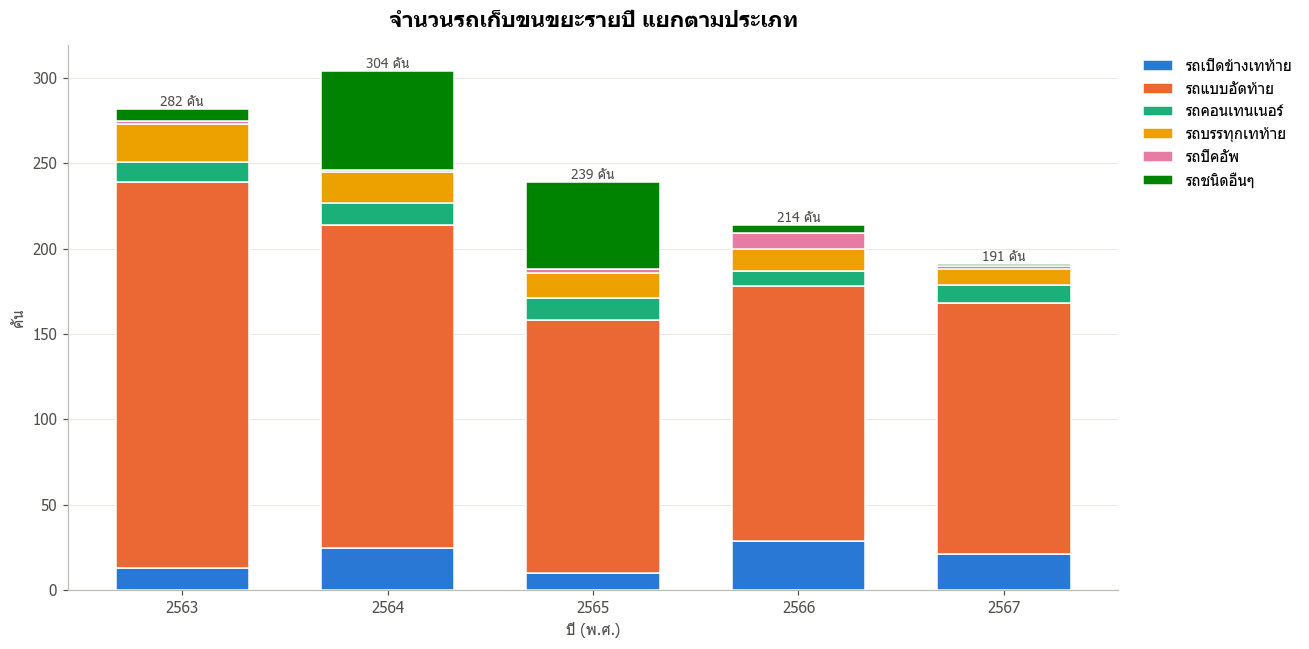

,รถเปิดข้างเทท้าย,รถแบบอัดท้าย,รถคอนเทนเนอร์,รถบรรทุกเทท้าย,รถปิคอัพ,รถชนิดอื่นๆ
ปี,,,,,,
2563,13,226,12,22,2,7
2564,25,189,13,18,1,58
2565,10,148,13,15,2,51
2566,29,149,9,13,9,5
2567,21,147,11,9,2,1


In [10]:
yearly = viz.groupby('ปี')[veh].sum()
fig, ax = plt.subplots(figsize=(12, 6))
totals = stacked_bar(ax, yearly, colors=[VEH_COLOR[v] for v in veh])
for i, t in enumerate(totals):
    ax.text(i, t, f'{t:,.0f} คัน', ha='center', va='bottom', fontsize=9, color=TEXT)
ax.set_title('จำนวนรถเก็บขนขยะรายปี แยกตามประเภท')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('คัน')
plt.tight_layout(); plt.show()
yearly

### 2.2 Pie chart: share of vehicle types (latest year)
**How to read it:** rear-loading compactors are the standard trucks — large capacity and hygienic. A high share means an efficient fleet

### 2.2 แผนภูมิวงกลม: สัดส่วนประเภทรถ (ปีล่าสุด)
**วิธีอ่าน:** รถแบบอัดท้าย (compactor) เป็นรถมาตรฐานที่บรรทุกได้มากและถูกสุขลักษณะ ถ้าสัดส่วนสูงแปลว่ากองรถมีประสิทธิภาพ

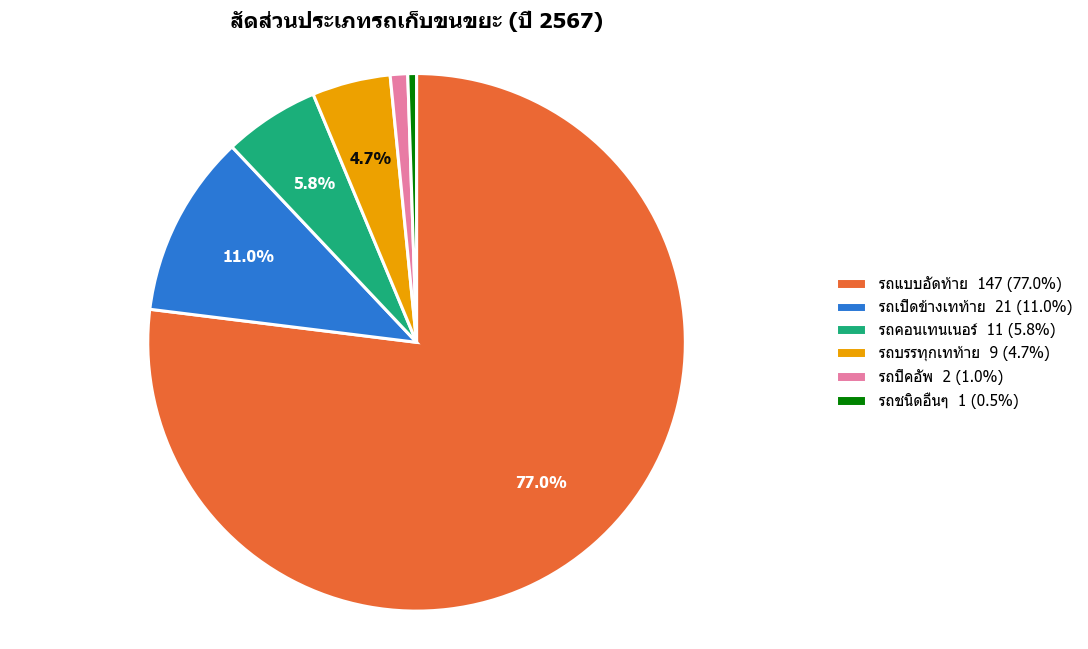

In [11]:
share = viz[viz['ปี'] == latest][veh].sum()
share = share[share > 0].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
pie_chart(ax, share.values, share.index, colors=[VEH_COLOR[v] for v in share.index],
          title=f'สัดส่วนประเภทรถเก็บขนขยะ (ปี {latest})')
plt.tight_layout(); plt.show()

### 2.3 Horizontal stacked bar chart: vehicles by district and type (latest year)
**How to read it:** the full bar length = the district's number of vehicles, sorted from fewest to most. Shows which vehicle types each district relies on

### 2.3 กราฟแท่งซ้อนแนวนอน: จำนวนรถรายอำเภอ แยกประเภท (ปีล่าสุด)
**วิธีอ่าน:** ความยาวทั้งแท่ง = จำนวนรถของอำเภอ เรียงจากน้อยไปมาก ดูว่าแต่ละอำเภอพึ่งพารถประเภทใด

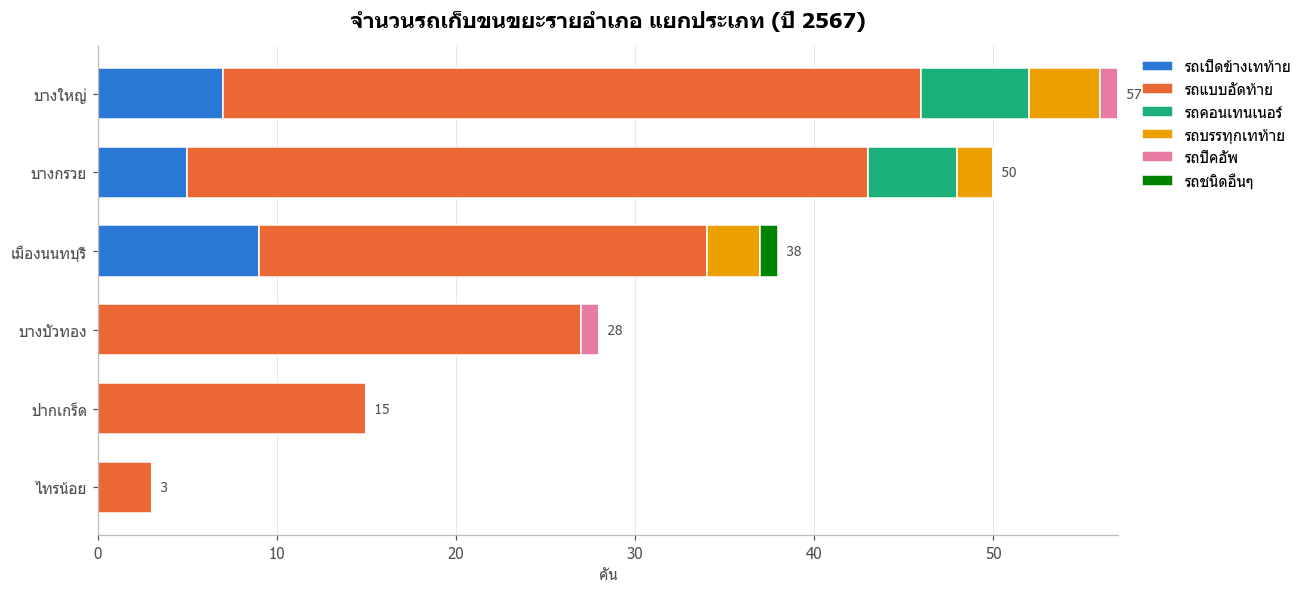

In [12]:
by_dist = viz[viz['ปี'] == latest].groupby('อำเภอ')[veh].sum()
by_dist = by_dist.loc[by_dist.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(12, 5.5))
totals = stacked_bar(ax, by_dist, colors=[VEH_COLOR[v] for v in veh], horizontal=True)
for i, t in enumerate(totals):
    ax.text(t, i, f'  {t:,.0f}', va='center', fontsize=9, color=TEXT)
ax.set_title(f'จำนวนรถเก็บขนขยะรายอำเภอ แยกประเภท (ปี {latest})'); ax.set_xlabel('คัน')
plt.tight_layout(); plt.show()

### 2.4 Horizontal bar chart: top 10 local governments with the most collection vehicles (latest year)

### 2.4 กราฟแท่งแนวนอน: 10 อปท. ที่มีรถเก็บขนมากที่สุด (ปีล่าสุด)

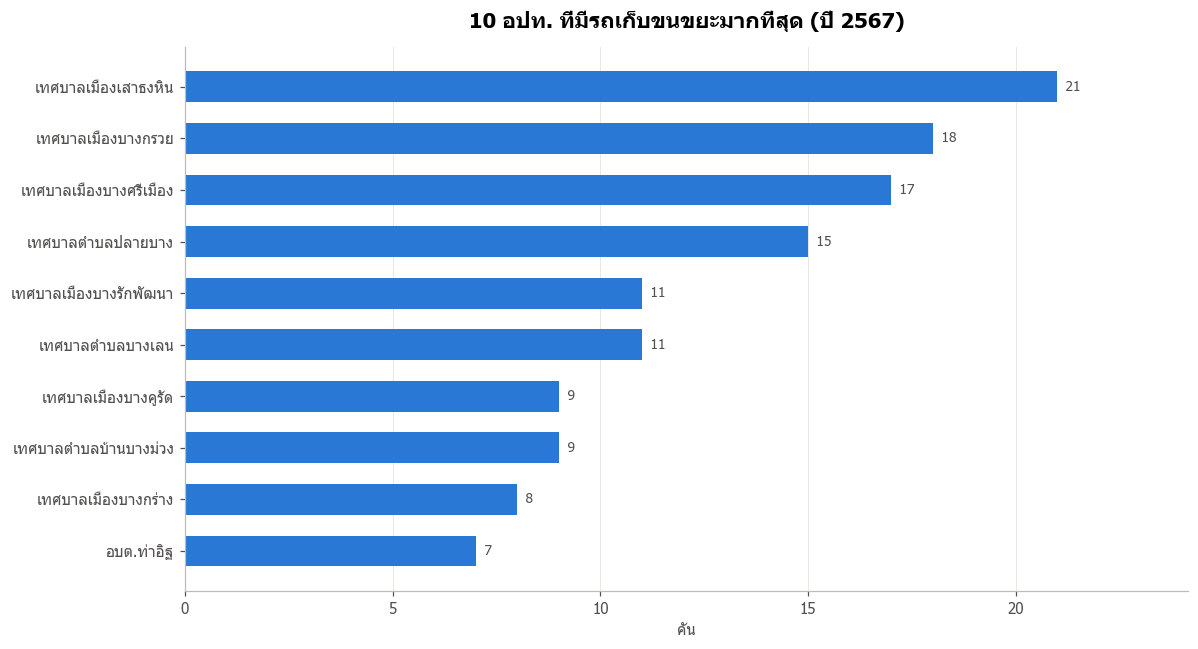

In [13]:
top = viz[viz['ปี'] == latest].groupby('อปท')['รถรวม'].sum().nlargest(10).sort_values()
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(top.index, top.values, color=PALETTE[0], height=0.6)
bar_labels(ax, bars, horizontal=True)
ax.set_xlim(0, top.max() * 1.15); ax.grid(axis='y', visible=False)
ax.set_title(f'10 อปท. ที่มีรถเก็บขนขยะมากที่สุด (ปี {latest})'); ax.set_xlabel('คัน')
plt.tight_layout(); plt.show()

### 2.5 Bar chart: waste load per vehicle (tonnes/vehicle/day) by district (latest year)
**What it does:** takes the year's total municipal solid waste (`clean_community.csv`) for the same year, divides it by the number of vehicles and by 365 days

`load per vehicle = yearly waste (tonnes) ÷ number of vehicles ÷ 365`

**How to read it:** a high value = each vehicle carries a heavy load, may need several trips or cannot keep up → the districts with the highest values should be considered first for more vehicles (dashed line = province average)

> Note: some local governments hire private contractors for collection (their vehicles are not in this data), which makes the load per vehicle in those districts look higher than it really is

### 2.5 กราฟแท่ง: ภาระขยะต่อรถ 1 คัน (ตัน/คัน/วัน) รายอำเภอ (ปีล่าสุด)
**ทำอะไร:** นำปริมาณขยะมูลฝอยชุมชนทั้งปี (`clean_community.csv`) ของปีเดียวกันมาหารด้วยจำนวนรถ และหารด้วย 365 วัน

`ภาระต่อรถ = ขยะทั้งปี (ตัน) ÷ จำนวนรถ ÷ 365`

**วิธีอ่าน:** ค่าสูง = รถแต่ละคันต้องรับภาระมาก อาจต้องวิ่งหลายรอบหรือเก็บไม่ทัน → อำเภอที่ค่าสูงสุดคือที่ควรพิจารณาเพิ่มรถก่อน (เส้นประ = ค่าเฉลี่ยทั้งจังหวัด)

> หมายเหตุ: อปท. บางแห่งจ้างเอกชนเก็บขน (รถไม่อยู่ในข้อมูลนี้) ทำให้ภาระต่อรถของอำเภอนั้นดูสูงเกินจริง

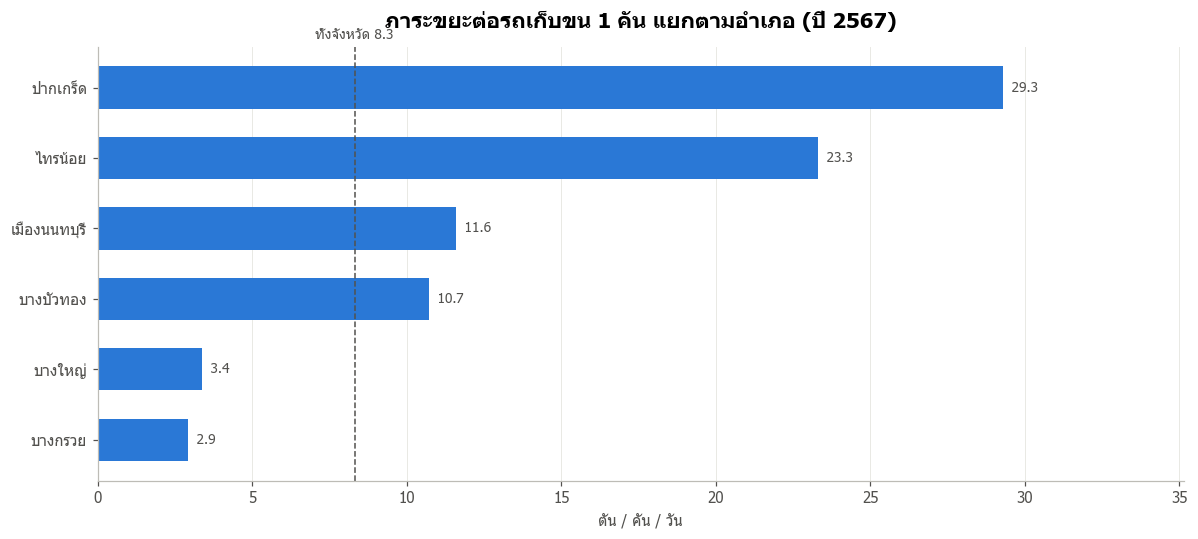

,ขยะทั้งปี (ตัน),จำนวนรถ (คัน),ตัน/คัน/วัน
อำเภอ,,,
บางกรวย,53371.8,50,2.9
บางบัวทอง,109514.0,28,10.7
บางใหญ่,70144.1,57,3.4
ปากเกร็ด,160374.9,15,29.3
เมืองนนทบุรี,160615.4,38,11.6
ไทรน้อย,25542.6,3,23.3


In [14]:
comm = pd.read_csv('../data/clean/clean_community.csv')
waste = comm[comm['ปี'] == latest].groupby('อำเภอ')['ขยะมูลฝอยชุมชน(ตัน)'].sum()
cars = viz[viz['ปี'] == latest].groupby('อำเภอ')['รถรวม'].sum()
load = (waste / cars / 365).replace(np.inf, np.nan).dropna().sort_values()
prov = waste.sum() / cars.sum() / 365
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(load.index, load.values, color=PALETTE[0], height=0.6)
bar_labels(ax, bars, fmt='{:.1f}', horizontal=True)
ax.set_xlim(0, load.max() * 1.2); ax.grid(axis='y', visible=False)
ref_line(ax, prov, f'ทั้งจังหวัด {prov:.1f}', axis='x')
ax.set_title(f'ภาระขยะต่อรถเก็บขน 1 คัน แยกตามอำเภอ (ปี {latest})'); ax.set_xlabel('ตัน / คัน / วัน')
plt.tight_layout(); plt.show()
pd.DataFrame({'ขยะทั้งปี (ตัน)': waste, 'จำนวนรถ (คัน)': cars, 'ตัน/คัน/วัน': waste / cars / 365}).round(1)

---
## Key Findings

1. **The number of collection vehicles is falling steadily**, from 304 (2564/2021) to 191 (2567/2024), or −37%
2. **Rear-loading compactors are the main vehicle (~77% in 2567)**, but they too dropped from 226 to 147
3. **The load per vehicle varies greatly between districts** — Pak Kret (~29 tonnes/vehicle/day) and Sai Noi (~23) are several times the province average (~8.3), while Bang Kruai and Bang Yai are around 3 tonnes/vehicle/day. Pak Kret may use private contractors' trucks (consistent with its high collection costs in the expenditure notebook), and Sai Noi has only 3 vehicles
4. **Recommendation:** districts with a high load per vehicle should check whether contracted vehicles are missing from the data before deciding to buy more vehicles

## สรุปข้อค้นพบ

1. **จำนวนรถเก็บขนลดลงต่อเนื่อง** จาก 304 คัน (2564) เหลือ 191 คัน (2567) หรือ −37%
2. **รถแบบอัดท้ายเป็นรถหลัก (~77% ในปี 2567)** แต่ก็ลดลงจาก 226 คันเหลือ 147 คัน
3. **ภาระต่อรถต่างกันมากระหว่างอำเภอ** — ปากเกร็ด (~29 ตัน/คัน/วัน) และไทรน้อย (~23) สูงกว่าค่าเฉลี่ยจังหวัด (~8.3) หลายเท่า ขณะที่บางกรวยและบางใหญ่อยู่ราว 3 ตัน/คัน/วัน — ปากเกร็ดอาจใช้รถเอกชน (สอดคล้องกับค่าเก็บขนที่สูงใน notebook ค่าใช้จ่าย) ส่วนไทรน้อยมีรถเพียง 3 คัน
4. **ข้อเสนอ:** อำเภอที่ภาระต่อรถสูงควรตรวจสอบว่ามีรถจ้างเหมาที่ไม่อยู่ในข้อมูลหรือไม่ ก่อนตัดสินใจจัดซื้อรถเพิ่ม